# Máscara da lesão (segmentar_otsu)

In [1]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

raiz do projeto: /home/isadora/Documentos/ProcessIMg


In [4]:
from src.preprocessamento import para_cinza
from src.segmentacao import segmentar_otsu, sobrepor

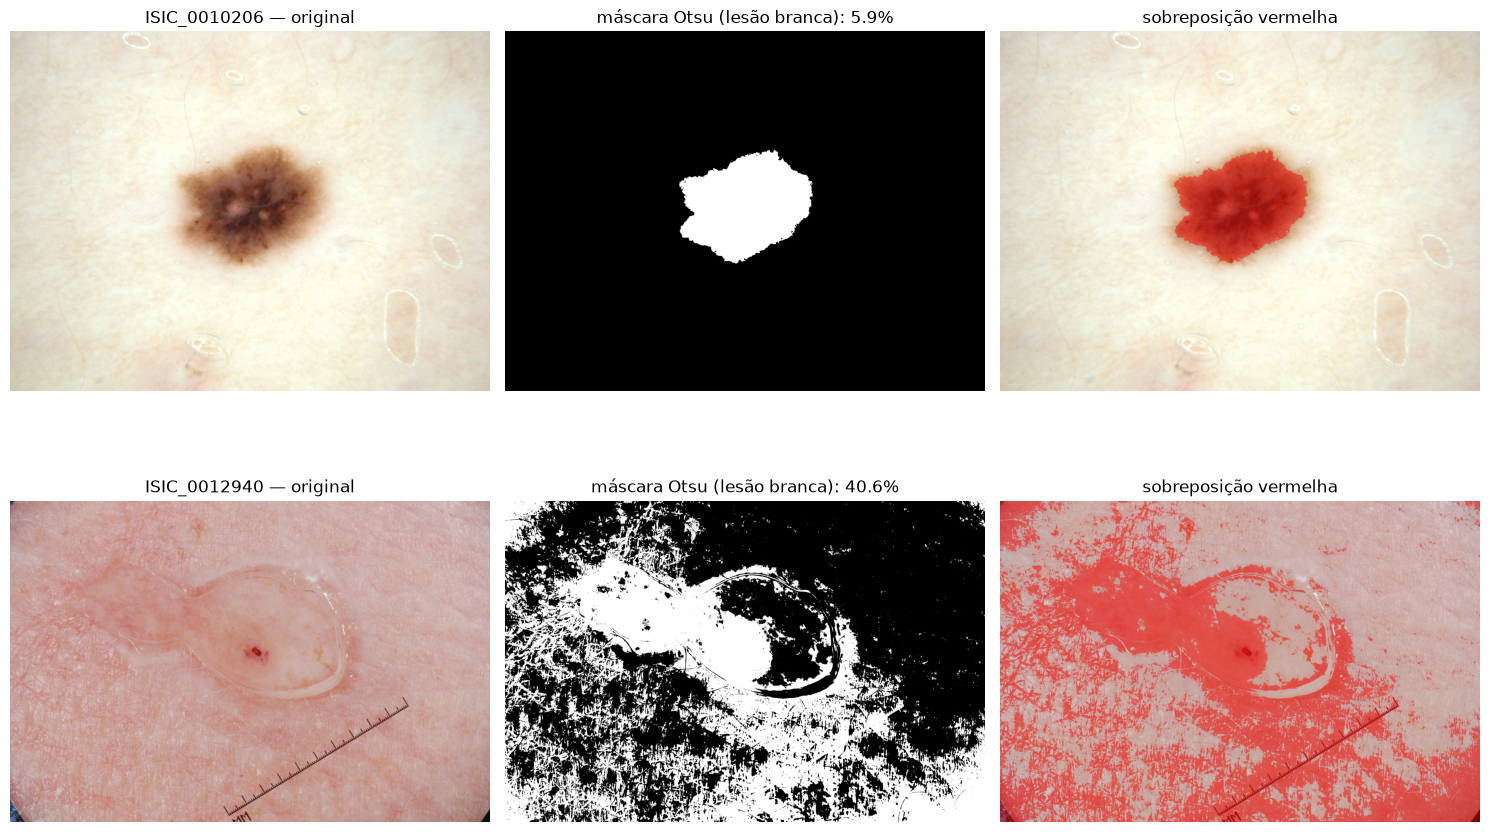

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i, nome in enumerate(["ISIC_0010206.jpg", "ISIC_0012940.jpg"]):
    img = carregar_imagem(PASTA_IMAGENS / nome)
    cinza = para_cinza(img)
    nome_curto = Path(nome).stem

    msk = segmentar_otsu(cinza)                     # lesão = branca (invertida por padrão)
    frac = msk.mean() / 255
    overlay = sobrepor(img, msk)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{nome_curto} — original")
    axes[i, 1].imshow(msk, cmap="gray")
    axes[i, 1].set_title(f"máscara Otsu (lesão branca): {frac*100:.1f}%")
    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("sobreposição vermelha")
    for ax in axes[i]:
        ax.axis("off")

fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "segmentadas" / "mascara_lesao.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)